Подключение библиотек и настройка папок

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter


# Путь к исходному изображению
IMAGE_PATH = Path("photos") / "original.png"

# Путь к папке с результатами
RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Библиотеки подключены!")
print("Папка для результатов подготовлена!")

Библиотеки подключены!
Папка для результатов подготовлена!


Загрузка и бинаризация изображения

In [51]:
# Загружаем изображение в оттенках серого
image = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_GRAYSCALE)

# Проверяем, удалось ли загрузить изображение
if image is None:
    raise FileNotFoundError(f"Изображение не найдено: {IMAGE_PATH}")

# Выполняем бинаризацию изображения
# Пиксели ярче 127 становятся белыми (255),
# остальные становятся чёрными (0)
_, binary_image = cv2.threshold(
    image,
    127,
    255,
    cv2.THRESH_BINARY
)

print("Изображение успешно загружено!")
print("Размер изображения:", binary_image.shape)

Изображение успешно загружено!
Размер изображения: (960, 1280)


Отображение исходного и бинаризованного изображений

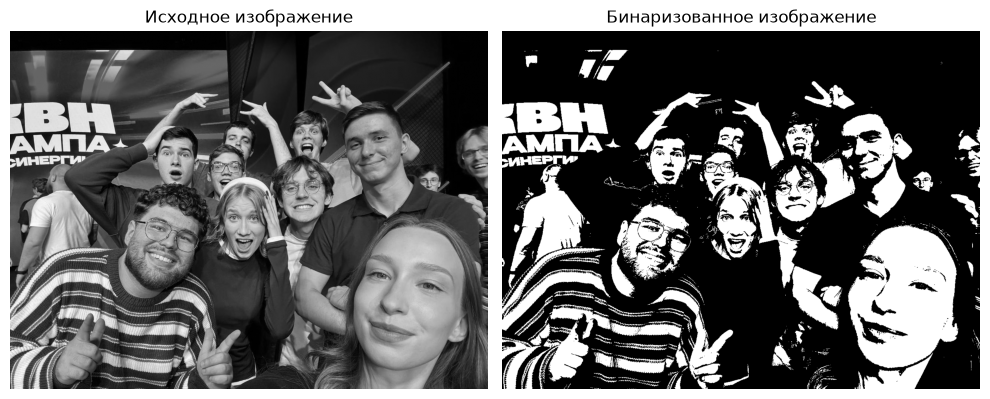

In [53]:
# Создаём область для двух изображений
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Исходное изображение
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Исходное изображение")
axes[0].axis("off")

# Бинаризованное изображение
axes[1].imshow(binary_image, cmap="gray")
axes[1].set_title("Бинаризованное изображение")
axes[1].axis("off")

# Настраиваем расположение изображений
fig.tight_layout()

# Сохраняем результат
fig.savefig(
    RESULTS_DIR / "input_and_binary.png",
    dpi=150,
    bbox_inches="tight"
)

# Показываем изображения
plt.show()

Реализация дилатации с помощью OpenCV

In [54]:
# Создаём структурный элемент размером 3 на 3
kernel = np.ones((3, 3), dtype=np.uint8)


# Функция дилатации с помощью OpenCV
def dilation_opencv(img):

    # Выполняем дилатацию
    result = cv2.dilate(
        img,
        kernel,
        iterations=1
    )

    return result


# Применяем дилатацию к изображению
opencv_result = dilation_opencv(binary_image)

print("Дилатация через OpenCV выполнена!")

Дилатация через OpenCV выполнена!


Самостоятельная реализация дилатации на Python

In [55]:
# Функция самостоятельной реализации дилатации
def dilation_manual(img):

    # Получаем высоту и ширину изображения
    height, width = img.shape

    # Создаём дополнительную рамку из чёрных пикселей
    # Она необходима для корректной обработки границ
    padded = np.zeros(
        (height + 2, width + 2),
        dtype=np.uint8
    )

    # Копируем изображение внутрь новой матрицы
    padded[1:-1, 1:-1] = img

    # Создаём пустое изображение для результата
    result = np.zeros_like(img)

    # Перебираем все строки изображения
    for y in range(height):

        # Перебираем все столбцы изображения
        for x in range(width):

            # Проверяем, есть ли белый пиксель среди соседей
            white_found = False

            # Перебираем соседние строки
            for dy in range(-1, 2):

                # Перебираем соседние столбцы
                for dx in range(-1, 2):

                    # Проверяем значение соседнего пикселя
                    if padded[y + 1 + dy, x + 1 + dx] == 255:

                        # Если нашли белый пиксель,
                        # запоминаем это
                        white_found = True

                        # Прекращаем проверку столбцов
                        break

                # Если белый пиксель найден,
                # прекращаем проверку строк
                if white_found:
                    break

            # Если хотя бы один сосед был белым,
            # делаем текущий пиксель белым
            if white_found:
                result[y, x] = 255

    # Возвращаем обработанное изображение
    return result


# Запускаем самостоятельную реализацию
python_result = dilation_manual(binary_image)

print("Самостоятельная дилатация выполнена!")

Самостоятельная дилатация выполнена!


Сравнение результатов

Результаты совпадают!
Количество различающихся пикселей: 0


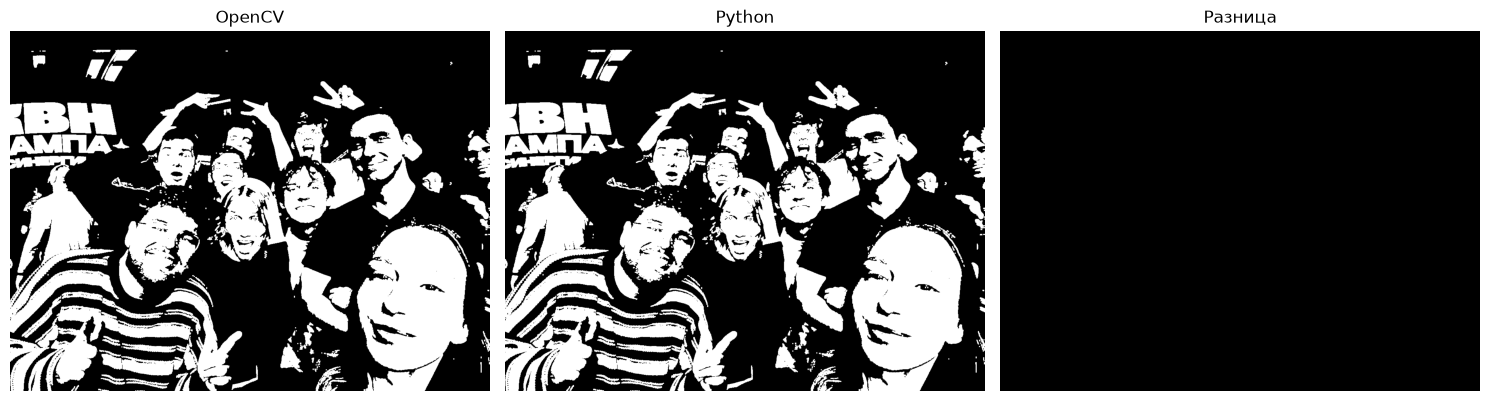

In [56]:
# Сравниваем результаты двух алгоритмов
if np.array_equal(opencv_result, python_result):
    print("Результаты совпадают!")
else:
    print("Результаты отличаются!")


# Находим разницу между результатами
difference = cv2.absdiff(
    opencv_result,
    python_result
)

# Считаем количество различающихся пикселей
different_pixels = np.count_nonzero(difference)

print(
    "Количество различающихся пикселей:",
    different_pixels
)


# Сохраняем обработанные изображения
cv2.imwrite(
    str(RESULTS_DIR / "binary.png"),
    binary_image
)

cv2.imwrite(
    str(RESULTS_DIR / "opencv_result.png"),
    opencv_result
)

cv2.imwrite(
    str(RESULTS_DIR / "python_result.png"),
    python_result
)


# Создаём область для трёх изображений
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Результат OpenCV
axes[0].imshow(opencv_result, cmap="gray")
axes[0].set_title("OpenCV")
axes[0].axis("off")

# Результат самостоятельной реализации
axes[1].imshow(python_result, cmap="gray")
axes[1].set_title("Python")
axes[1].axis("off")

# Разница между результатами
axes[2].imshow(difference, cmap="gray")
axes[2].set_title("Разница")
axes[2].axis("off")

# Настраиваем расположение изображений
fig.tight_layout()

# Сохраняем результат сравнения
fig.savefig(
    RESULTS_DIR / "dilation_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

# Показываем изображения
plt.show()

Функция измерения времени

In [57]:
# Функция измерения среднего времени выполнения
def measure_time(function, img, repeats=100):

    # Первый запуск для предварительного выполнения функции
    function(img)

    # Запоминаем время начала
    start = perf_counter()

    # Выполняем алгоритм несколько раз
    for _ in range(repeats):
        function(img)

    # Запоминаем время окончания
    end = perf_counter()

    # Возвращаем среднее время одного выполнения
    return (end - start) / repeats

Сравнение быстродействия

In [58]:
# Размеры изображений для тестирования
sizes = [128, 256, 512]

# Списки для хранения времени выполнения
opencv_times = []
python_times = []


# Перебираем размеры изображений
for max_side in sizes:

    # Получаем исходные размеры изображения
    height, width = binary_image.shape

    # Рассчитываем коэффициент изменения размера
    scale = max_side / max(height, width)

    # Рассчитываем новые размеры
    new_width = max(1, int(width * scale))
    new_height = max(1, int(height * scale))

    # Изменяем размер изображения с сохранением пропорций
    test_image = cv2.resize(
        binary_image,
        (new_width, new_height),
        interpolation=cv2.INTER_NEAREST
    )

    # Измеряем время OpenCV (1000 повторений)
    cv_time = measure_time(
        dilation_opencv,
        test_image,
        repeats=1000
    )

    # Измеряем время самостоятельного алгоритма (10 повторений)
    py_time = measure_time(
        dilation_manual,
        test_image,
        repeats=10
    )

    # Сохраняем результаты
    opencv_times.append(cv_time)
    python_times.append(py_time)

    # Рассчитываем, во сколько раз Python медленнее OpenCV
    speedup = py_time / cv_time if cv_time > 0 else float("inf")

    # Выводим результаты
    print(
        f"Размер: {max_side} ({new_width}x{new_height}) | "
        f"OpenCV: {cv_time:.8f} сек | "
        f"Python: {py_time:.6f} сек | "
        f"Разница: {speedup:.0f} раз"
    )

Размер: 128 (128x96) | OpenCV: 0.00000680 сек | Python: 0.016332 сек | Разница: 2403 раз
Размер: 256 (256x192) | OpenCV: 0.00001264 сек | Python: 0.076579 сек | Разница: 6059 раз
Размер: 512 (512x384) | OpenCV: 0.00002893 сек | Python: 0.316417 сек | Разница: 10938 раз


Построение и сохранение графика

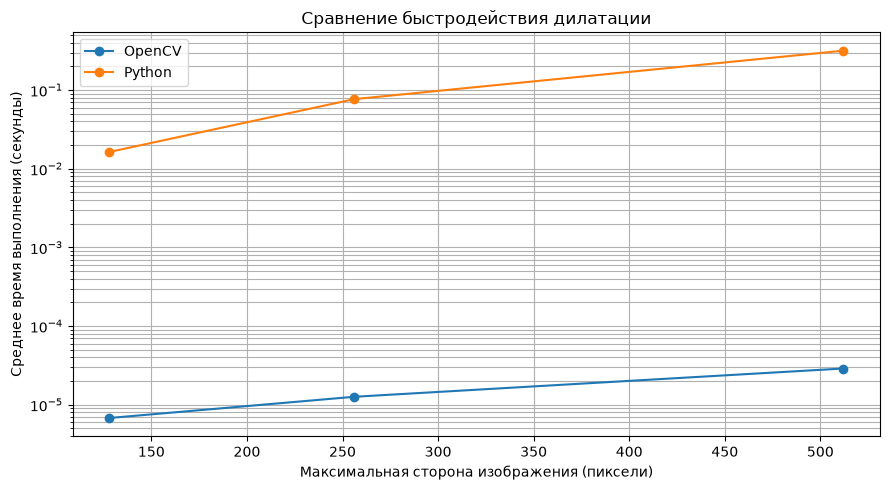

Все результаты сохранены в папку results!


In [59]:
# Создаём график
plt.figure(figsize=(9, 5))

# График скорости OpenCV
plt.plot(
    sizes,
    opencv_times,
    marker="o",
    label="OpenCV"
)

# График скорости Python
plt.plot(
    sizes,
    python_times,
    marker="o",
    label="Python"
)

# Подписываем оси
plt.xlabel("Максимальная сторона изображения (пиксели)")
plt.ylabel("Среднее время выполнения (секунды)")

# Заголовок графика
plt.title("Сравнение быстродействия дилатации")

# Используем логарифмическую шкалу
plt.yscale("log")

# Добавляем легенду и сетку
plt.legend()
plt.grid(True, which="both")

# Настраиваем расположение элементов
plt.tight_layout()

# Сохраняем график
plt.savefig(
    RESULTS_DIR / "performance.png",
    dpi=150,
    bbox_inches="tight"
)

# Показываем график
plt.show()

print("Все результаты сохранены в папку results!")